# The Hubbard model for two electrons on a ring

This notebook helps solving Problem Set 2 on two electrons on a ring.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import linalg as LA

### Model parameters

In [2]:
t=1.
U=2.
L=6

We consider the two particle states with total crystal momentum zero, i.e. the states $|k \uparrow, -k \downarrow>$. There are $L$ states because $k$ can take on the values $k= 2\pi*(0,1/L,2/L,\ldots,(L-1)/L)$.

In [3]:
k=2*np.pi*np.arange(L)/L

In [4]:
k

array([0.        , 1.04719755, 2.0943951 , 3.14159265, 4.1887902 ,
       5.23598776])

The kinetic energy operator:

In [5]:
HTB=np.diag(-t*np.cos(k)-t*np.cos(-k))

The Coulomb/Hubbard term

In [6]:
HC=U/L*np.ones((L,L))

In [7]:
H=HTB+HC

In [8]:
e,psi=LA.eigh(H)

In [9]:
energies=[]
for U in np.arange(0,4,.1):
    HC=U/L*np.ones((L,L))
    H=HTB+HC
    e,psi=LA.eigh(H)
    energies.append(e)

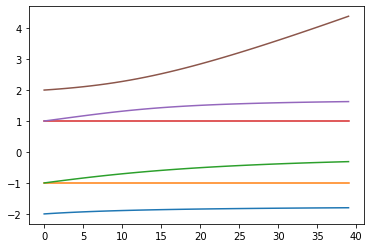

In [10]:
plt.plot(energies)

Now lets look more at the ground state in detail for U=2 (You can try different U's and see what happens)

In [25]:
U=200.
HC=U/L*np.ones((L,L))
H=HTB+HC
e,psi=LA.eigh(H)
psi0=psi[:,0]

Transform to real space. The wave function depends only on the distance n0=n-n' between the two sites.
The transformation is $$\Psi(n \uparrow, n^\prime \downarrow) = \frac{1}{L} \sum_k e^{i(n-n^\prime)k} \Psi(k \uparrow,-k \downarrow)$$

In [26]:
transform=1/float(L)*np.asarray([[np.exp(1j * n*k0) for k0 in k] for n in range(L)])

In [27]:
psi0n=transform.dot(psi0)

In [19]:
psi0n

array([0.01127701+0.00000000e+00j, 0.12262627+1.87350135e-16j,
       0.20307467+2.56739074e-16j, 0.23234984-3.05592428e-17j,
       0.20307467-2.91433544e-16j, 0.12262627-2.56739074e-16j])

(0.0, 5.0, 0.0, 0.3656102558338219)

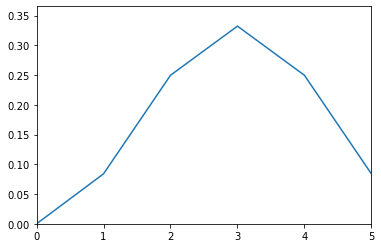

In [28]:
plt.plot(L*abs(psi0n)**2)
plt.axis([0,5,0,1.1*max(L*abs(psi0n)**2)])

In [28]:
sum(abs(psi0n)**2)*6

1.0